# Przeszukiwanie siatki parametrów (Grid Search)

**Plan notatnika:**
1. Po co przeszukiwać hiperparametry
2. Dane i punkt odniesienia
3. `GridSearchCV` – pierwszy przykład (drzewo decyzyjne)
4. Wyniki przeszukiwania: `cv_results_` i mapa cieplna
5. Ocena końcowa na zbiorze testowym
6. Siatka zależnych parametrów (lista słowników) – SVM
7. Przeszukiwanie hiperparametrów potoku
8. Wybór metryki (`scoring`)
9. `RandomizedSearchCV` – szybsza alternatywa
10. Pułapki i dobre praktyki
11. Podsumowanie

## 1. Po co przeszukiwać hiperparametry

**Hiperparametry** to ustawienia modelu, które wybieramy **przed** uczeniem (np. `max_depth` drzewa), w odróżnieniu od **parametrów**, które model uczy się sam (rozdział 2.3). Mają duży wpływ na jakość – zbyt mała głębokość drzewa to niedouczenie, zbyt duża – przeuczenie (rozdział 4.3).

Ręczne próbowanie kolejnych wartości jest żmudne i łatwo je zrobić nierzetelnie. **Przeszukiwanie siatki** (*grid search*) robi to systematycznie:

1. definiujemy **siatkę** – listę wartości dla każdego hiperparametru,
2. sprawdzamy **każdą kombinację** (stąd „siatka”),
3. każdą kombinację oceniamy **walidacją krzyżową** (rozdział 4.4),
4. wybieramy kombinację o najlepszej średniej ocenie.

Liczba trenowań modelu to **liczba kombinacji × liczba foldów**, więc koszt szybko rośnie: np. 3 hiperparametry po 10 wartości i `cv=5` to 5000 trenowań.

## 2. Dane i punkt odniesienia

Użyjemy znanych już „księżyców” (`make_moons`). Zbiór dzielimy na treningowy i testowy – **strojenie wykonamy wyłącznie na treningowym**, a zbiór testowy zostawimy na końcową ocenę.

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.model_selection import (train_test_split, cross_val_score,
                                     GridSearchCV, RandomizedSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

np.random.seed(42)

In [3]:
X, y = make_moons(n_samples=2000, noise=0.25, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

print(f'Zbiór treningowy: {X_train.shape}, testowy: {X_test.shape}')

Zbiór treningowy: (1500, 2), testowy: (500, 2)


In [4]:
# Punkt odniesienia: drzewo z domyślnymi hiperparametrami
domyslne = DecisionTreeClassifier(random_state=42)
wynik = cross_val_score(domyslne, X_train, y_train, cv=5)
print(f'Drzewo z domyślnymi hiperparametrami, walidacja krzyżowa: {wynik.mean():.3f} (+/- {wynik.std():.3f})')

Drzewo z domyślnymi hiperparametrami, walidacja krzyżowa: 0.931 (+/- 0.015)


## 3. `GridSearchCV` – pierwszy przykład

Dla drzewa decyzyjnego przeszukamy dwa hiperparametry:

- `max_depth` – maksymalna głębokość drzewa (od 1 do 10),
- `min_samples_leaf` – minimalna liczba obserwacji w liściu.

Siatkę podajemy jako **słownik**: nazwa hiperparametru → lista wartości. Najważniejsze argumenty `GridSearchCV`:

| Argument | Znaczenie |
|---|---|
| `estimator` | model do strojenia |
| `param_grid` | siatka hiperparametrów |
| `cv` | liczba foldów lub strategia podziału (rozdział 4.4) |
| `scoring` | metryka, według której wybieramy najlepszy model |
| `n_jobs=-1` | liczba zadań liczonych **równolegle**; `-1` = wszystkie rdzenie procesora, `1` (domyślnie) = jedno zadanie po drugim |
| `refit=True` (domyślnie) | po przeszukaniu uczy najlepszy model **ponownie na całym zbiorze treningowym** |

**Jak działa `n_jobs`:** każda kombinacja hiperparametrów w każdym foldzie to niezależne trenowanie modelu, więc wiele z nich można liczyć jednocześnie na różnych rdzeniach procesora. Przy `n_jobs=-1` komputer z 8 rdzeniami liczy do 8 trenowań naraz, więc przeszukiwanie trwa wielokrotnie krócej (w praktyce nieco mniej niż 8 razy). Parametr wpływa tylko na czas, **nie na wynik**.

In [5]:
siatka = {
    'max_depth': list(range(1, 11)),
    'min_samples_leaf': [1, 2, 3, 5, 8, 10, 15, 20],
}
liczba_kombinacji = len(siatka['max_depth']) * len(siatka['min_samples_leaf'])
print(f'Kombinacji: {liczba_kombinacji}, trenowań (przy cv=5): {liczba_kombinacji * 5}')

grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid=siatka,
                    scoring='accuracy', cv=5, n_jobs=-1)
grid.fit(X_train, y_train)

print('Najlepsze hiperparametry:', grid.best_params_)
print(f'Najlepszy wynik walidacji krzyżowej: {grid.best_score_:.3f}')

Kombinacji: 80, trenowań (przy cv=5): 400
Najlepsze hiperparametry: {'max_depth': 8, 'min_samples_leaf': 5}
Najlepszy wynik walidacji krzyżowej: 0.943


Po dopasowaniu obiekt `grid` zawiera m.in.:

- `best_params_` – najlepsza kombinacja,
- `best_score_` – średni wynik walidacji krzyżowej dla tej kombinacji,
- `best_estimator_` – model z najlepszymi hiperparametrami, **już nauczony** na całym zbiorze treningowym (dzięki `refit=True`),
- `cv_results_` – szczegółowe wyniki wszystkich kombinacji.

Sam `grid` zachowuje się jak model: ma `predict`, `predict_proba` i `score`, które korzystają z `best_estimator_`.

## 4. Wyniki przeszukiwania: `cv_results_` i mapa cieplna

Wyniki wszystkich kombinacji najwygodniej obejrzeć w tabeli:

In [6]:
wyniki = pd.DataFrame(grid.cv_results_)
kolumny = ['param_max_depth', 'param_min_samples_leaf', 'mean_test_score', 'std_test_score', 'rank_test_score']

wyniki[kolumny].sort_values('rank_test_score').head(10).round(3)

,param_max_depth,param_min_samples_leaf,mean_test_score,std_test_score,rank_test_score
59,8,5,0.943,0.013,1
47,6,20,0.942,0.014,2
55,7,20,0.942,0.014,2
60,8,8,0.942,0.014,2
63,8,20,0.942,0.014,2
67,9,5,0.942,0.013,2
68,9,8,0.942,0.014,2
79,10,20,0.942,0.014,2
71,9,20,0.942,0.014,2
75,10,5,0.942,0.013,2


Kolumna `mean_test_score` to średnia ocena z foldów walidacyjnych, `std_test_score` – jej rozrzut, a `rank_test_score` – pozycja kombinacji w rankingu. Zobaczmy cały wynik jako **mapę cieplną** (głębokość × minimalna liczba obserwacji w liściu):

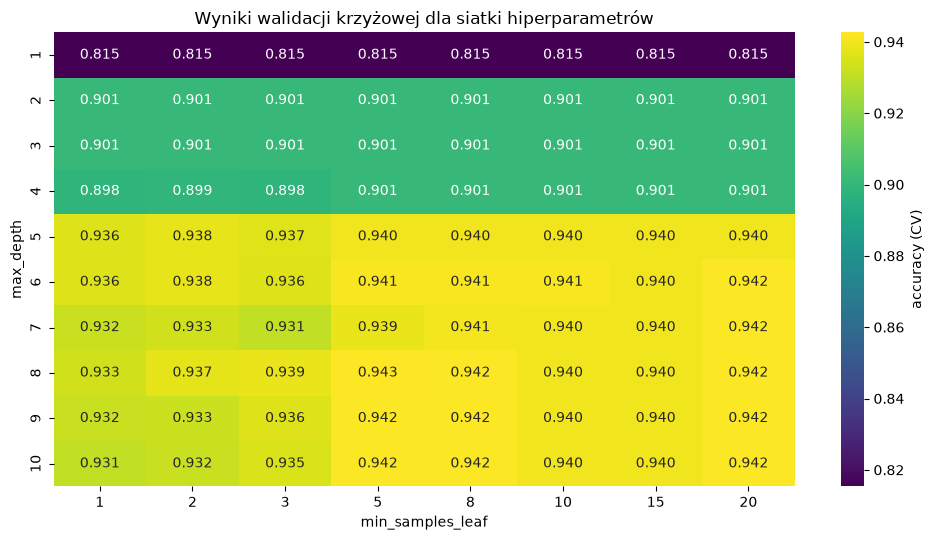

In [7]:
mapa = wyniki.pivot(index='param_max_depth', columns='param_min_samples_leaf', values='mean_test_score').astype(float)

plt.figure(figsize=(10, 5.5))
sns.heatmap(mapa, annot=True, fmt='.3f', cmap='viridis', cbar_kws={'label': 'accuracy (CV)'})
plt.xlabel('min_samples_leaf')
plt.ylabel('max_depth')
plt.title('Wyniki walidacji krzyżowej dla siatki hiperparametrów')
plt.tight_layout()
plt.show()

Mapa cieplna pokazuje więcej niż sam ranking:

- Dla **małej głębokości** (1–4) wyniki są wyraźnie gorsze (dla `max_depth=1` ok. 0,82, dla 2–4 ok. 0,90) – **niedouczenie**. W tym zakresie `min_samples_leaf` nic nie zmienia, bo drzewo i tak ma za mało poziomów, by liście były małe.
- Od głębokości 5 wyniki układają się w **płaskowyż** (ok. 0,94): wiele kombinacji daje niemal identyczny wynik, a różnice mieszczą się w granicach rozrzutu (`std_test_score`). Wybór „najlepszej” z nich jest w dużej mierze kwestią przypadku.
- Przy **dużej głębokości i małym `min_samples_leaf`** wyniki nieznacznie spadają – **przeuczenie**.

Gdy wiele kombinacji daje podobny wynik, rozsądnie wybrać **najprostszy model** (płytsze drzewo, większy `min_samples_leaf`) – będzie stabilniejszy i łatwiejszy do interpretacji.

## 5. Ocena końcowa na zbiorze testowym

Dopiero teraz używamy zbioru testowego – **raz**, dla ostatecznie wybranego modelu.

Domyślne drzewo (trening/test):  1.000 / 0.920
Po strojeniu (trening/test):     0.963 / 0.930


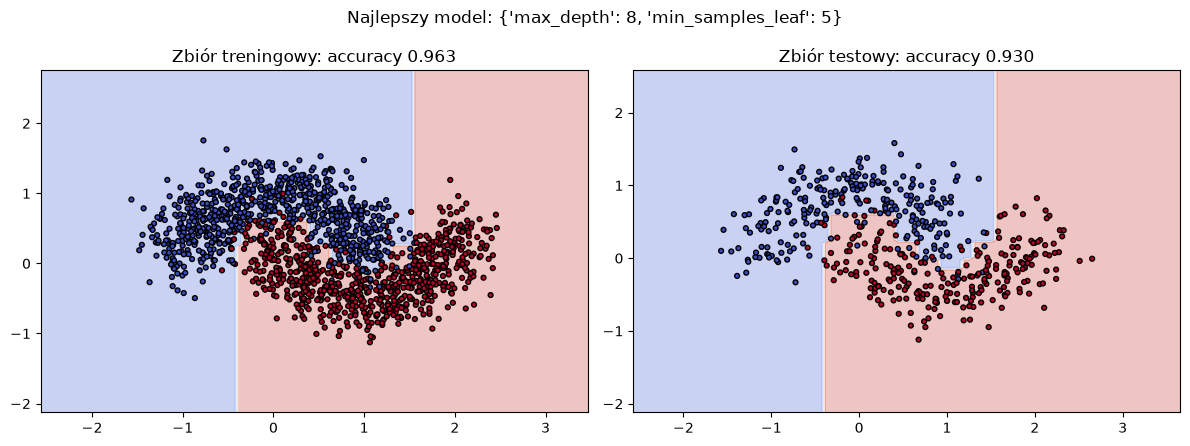

In [8]:
print(f'Domyślne drzewo (trening/test):  {domyslne.fit(X_train, y_train).score(X_train, y_train):.3f} / {domyslne.score(X_test, y_test):.3f}')
print(f'Po strojeniu (trening/test):     {grid.score(X_train, y_train):.3f} / {grid.score(X_test, y_test):.3f}')

fig, osie = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (X_z, y_z, opis) in zip(osie, [(X_train, y_train, 'treningowy'), (X_test, y_test, 'testowy')]):
    DecisionBoundaryDisplay.from_estimator(grid.best_estimator_, X_z, ax=ax,
                                           response_method='predict', cmap='coolwarm', alpha=0.3)
    ax.scatter(X_z[:, 0], X_z[:, 1], c=y_z, cmap='coolwarm', edgecolor='k', s=12)
    ax.set_title(f'Zbiór {opis}: accuracy {grid.score(X_z, y_z):.3f}')
fig.suptitle(f'Najlepszy model: {grid.best_params_}')
plt.tight_layout()
plt.show()

Strojenie ogranicza przeuczenie: różnica między wynikiem na zbiorze treningowym a testowym jest mniejsza niż dla drzewa domyślnego, a wynik testowy nieco lepszy. Zysk jest umiarkowany (drzewo domyślne było już dość dobre). Wynik testowy jest też nieco niższy niż `best_score_` – to typowe (punkt 10).

## 6. Siatka zależnych parametrów (lista słowników) – SVM

**SVM** (*Support Vector Machine*, maszyna wektorów nośnych) to model, który szuka granicy między klasami tak, by **margines** (odstęp od najbliższych obserwacji obu klas) był jak największy. **`SVC`** (*Support Vector Classifier*) to jego klasyfikator w scikit-learn. Najważniejsze hiperparametry:

| Hiperparametr | Znaczenie |
|---|---|
| `kernel` | kształt granicy decyzyjnej: `linear` – linia prosta, `rbf` – krzywa, elastyczna granica |
| `C` | tolerancja błędów na zbiorze treningowym: małe `C` – szerszy margines i więcej dopuszczonych błędów (model prostszy), duże `C` – model mocno dopasowuje się do danych treningowych (ryzyko przeuczenia) |
| `gamma` | tylko dla `rbf`: zasięg wpływu pojedynczej obserwacji; małe `gamma` – granica gładka, duże `gamma` – bardzo „poszarpana” (ryzyko przeuczenia) |

Nie wszystkie hiperparametry mają sens dla każdej wartości innego hiperparametru: `gamma` działa tylko dla jądra `rbf`, a nie dla `linear`. Pełna siatka (iloczyn kartezjański) powielałaby więc kombinacje, które dają ten sam model.

W takiej sytuacji podajemy **listę słowników** – każdy opisuje osobną „podsiatkę”:

In [9]:
siatka_svm = [
    {'kernel': ['linear'], 'C': [0.1, 1, 10]},
    {'kernel': ['rbf'], 'C': [0.1, 1, 10, 100], 'gamma': [0.1, 1, 10]},
]

grid_svm = GridSearchCV(SVC(), param_grid=siatka_svm, cv=5, scoring='accuracy', n_jobs=-1)
grid_svm.fit(X_train, y_train)

print('Najlepsze hiperparametry:', grid_svm.best_params_)
print(f'Wynik walidacji krzyżowej: {grid_svm.best_score_:.3f}')
print(f'Wynik na zbiorze testowym: {grid_svm.score(X_test, y_test):.3f}')
print(f'Liczba kombinacji: {len(grid_svm.cv_results_["params"])} (zamiast {2 * 3 * 4 * 3} w pełnym iloczynie)')

Najlepsze hiperparametry: {'C': 0.1, 'gamma': 10, 'kernel': 'rbf'}
Wynik walidacji krzyżowej: 0.949
Wynik na zbiorze testowym: 0.936
Liczba kombinacji: 15 (zamiast 72 w pełnym iloczynie)


Zwróćmy uwagę, że najlepsze wartości (`C=0.1`, `gamma=10`) leżą na **brzegu** siatki. To sygnał, że optimum może być poza nią, więc warto rozszerzyć siatkę w tym kierunku (np. o `C=0.01` i `gamma=100`) i powtórzyć wyszukiwanie.

## 7. Przeszukiwanie hiperparametrów potoku

SVM opiera się na odległościach między obserwacjami, więc jest wrażliwy na skalę cech i zwykle skalujemy dane. Skaler umieszczamy **w potoku** (rozdział 4.4, wyciek danych) i przeszukujemy hiperparametry całego potoku.

Potok `make_pipeline(StandardScaler(), SVC())` składa się z dwóch kroków wykonywanych po kolei:
1. `StandardScaler()` – standaryzuje cechy (średnia 0, odchylenie standardowe 1),
2. `SVC()` – klasyfikator SVM opisany w punkcie 6, uczony na tak przygotowanych danych. Nazwy hiperparametrów zapisujemy w formacie **`nazwa_kroku__hiperparametr`** (dwa podkreślniki). Nazwę kroku tworzy `make_pipeline` z nazwy klasy małymi literami, np. `svc`.

In [10]:
potok = make_pipeline(StandardScaler(), SVC())
print('Kroki potoku:', list(potok.named_steps))

siatka_potok = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': [0.01, 0.1, 1, 10],
}

grid_potok = GridSearchCV(potok, param_grid=siatka_potok, cv=5, n_jobs=-1)
grid_potok.fit(X_train, y_train)

print('Najlepsze hiperparametry:', grid_potok.best_params_)
print(f'Wynik walidacji krzyżowej: {grid_potok.best_score_:.3f}')
print(f'Wynik na zbiorze testowym: {grid_potok.score(X_test, y_test):.3f}')

Kroki potoku: ['standardscaler', 'svc']
Najlepsze hiperparametry: {'svc__C': 1, 'svc__gamma': 1}
Wynik walidacji krzyżowej: 0.949
Wynik na zbiorze testowym: 0.934


W każdym foldzie skaler jest uczony od nowa tylko na części uczącej, więc przeszukiwanie jest wolne od wycieku danych. To właśnie powód, dla którego przy strojeniu modeli z przygotowaniem danych używamy potoków.

## 8. Wybór metryki (`scoring`)

Domyślnie klasyfikatory są oceniane przez `accuracy`. Dla danych niezbalansowanych (rozdział 4.3) wybierzemy inną metrykę, np. `'f1'` lub `'roc_auc'`. Nazwy dostępnych metryk zwraca `sklearn.metrics.get_scorer_names()`.

Można też liczyć **kilka metryk naraz**, wskazując, według której wybierać najlepszy model (`refit`):

```python
GridSearchCV(model, siatka, scoring=['accuracy', 'f1', 'roc_auc'], refit='f1', cv=5)
```

Wtedy `cv_results_` zawiera kolumny `mean_test_accuracy`, `mean_test_f1` i `mean_test_roc_auc`.

## 9. `RandomizedSearchCV` – szybsza alternatywa

Gdy hiperparametrów jest dużo, pełna siatka staje się zbyt kosztowna. **`RandomizedSearchCV`** zamiast sprawdzać wszystkie kombinacje **losuje** ich ustaloną liczbę (`n_iter`) z podanych list lub **rozkładów**. Dzięki temu:

- czas jest kontrolowany przez `n_iter`, niezależnie od rozmiaru przestrzeni,
- dla hiperparametrów ciągłych lub całkowitych o dużym zakresie możemy podać **rozkład** (np. `randint`) zamiast ręcznie wybranych wartości,
- w praktyce często znajduje wynik niewiele gorszy od pełnej siatki, w znacznie krótszym czasie.

Porównajmy oba podejścia dla lasu losowego (rozdział 4.2).

In [11]:
siatka_rf = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 8, None],
    'min_samples_leaf': [1, 3, 5, 10],
    'max_features': ['sqrt', None],
}
liczba = np.prod([len(v) for v in siatka_rf.values()])

start = time.perf_counter()
grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), siatka_rf, cv=5, n_jobs=-1)
grid_rf.fit(X_train, y_train)
czas_grid = time.perf_counter() - start

print(f'GridSearchCV: {liczba} kombinacji, {czas_grid:.1f} s')
print(f'  najlepszy wynik CV: {grid_rf.best_score_:.3f}, test: {grid_rf.score(X_test, y_test):.3f}')
print(f'  {grid_rf.best_params_}')

GridSearchCV: 64 kombinacji, 6.1 s
  najlepszy wynik CV: 0.952, test: 0.932
  {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 200}


In [12]:
rozklady_rf = {
    'n_estimators': randint(50, 300),
    'max_depth': randint(2, 12),
    'min_samples_leaf': randint(1, 15),
    'max_features': ['sqrt', None],
}

start = time.perf_counter()
random_rf = RandomizedSearchCV(RandomForestClassifier(random_state=42), rozklady_rf,
                               n_iter=15, cv=5, n_jobs=-1, random_state=42)
random_rf.fit(X_train, y_train)
czas_random = time.perf_counter() - start

print(f'RandomizedSearchCV: 15 kombinacji, {czas_random:.1f} s')
print(f'  najlepszy wynik CV: {random_rf.best_score_:.3f}, test: {random_rf.score(X_test, y_test):.3f}')
print(f'  {random_rf.best_params_}')

RandomizedSearchCV: 15 kombinacji, 1.4 s
  najlepszy wynik CV: 0.951, test: 0.934
  {'max_depth': 9, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 152}


`RandomizedSearchCV` sprawdziło tylko ułamek kombinacji i wymagało znacznie mniej czasu, a uzyskany wynik jest zbliżony do wyniku pełnej siatki. Wynika to z płaskowyżu, który widzieliśmy na mapie cieplnej: wiele ustawień daje niemal tak samo dobry model, więc nie trzeba sprawdzać każdego.

Dodatkowo `RandomizedSearchCV` może badać **więcej różnych wartości** każdego hiperparametru niż siatka o tym samym koszcie, bo nie jest ograniczone ręcznie wybraną listą.

## 10. Pułapki i dobre praktyki

1. **`best_score_` jest nieco optymistyczny.** Wybraliśmy najlepszy z wielu wyników, więc częściowo „dopasowaliśmy się” do danych walidacyjnych. Prawdziwą jakość oceniamy na **zbiorze testowym**, który nie brał udziału w strojeniu (dokładniejsza, ale kosztowna metoda to *nested cross-validation*, czyli zagnieżdżona walidacja krzyżowa).
2. **Nie stroimy na zbiorze testowym.** Cały proces strojenia wykonujemy na zbiorze treningowym.
3. **Zaczynamy od szerokiej, rzadkiej siatki** (np. `C`: 0,1; 1; 10; 100), a potem **zawężamy** ją wokół najlepszych wartości.
4. **Hiperparametry typu `C`, `gamma`, `alpha` próbkujemy na skali logarytmicznej.** Ich wpływ na model widać dopiero przy zmianie o **rząd wielkości** (np. z 0,1 na 1 albo na 10), a prawie wcale przy zmianie o jednostkę (z 10 na 11). Dlatego wartości wybieramy co mnożnik 10: 0,001; 0,01; 0,1; 1; 10; 100 (można je wygenerować przez `np.logspace(-3, 2, 6)`). Siatka liniowa, np. 1, 2, 3, 4, 5, sprawdzałaby tylko wąski zakres i pomijała wartości takie jak 0,01 czy 100.
5. **Pilnujemy kosztu:** liczba trenowań = kombinacje × `cv`. Używamy `n_jobs=-1`, a dla dużych przestrzeni – `RandomizedSearchCV`.
6. **Ustawiamy `random_state`** modelu i walidacji, aby wyniki były powtarzalne.
7. **Strojenie ma ograniczony zysk.** Dane i cechy (rozdział 2.4) zwykle mają większy wpływ na jakość modelu niż hiperparametry; strojenie to ostatni szlif.
8. W projektach o dużej przestrzeni poszukiwań stosuje się też **optymalizację bayesowską** (np. biblioteka Optuna), która wybiera kolejne kombinacje na podstawie dotychczasowych wyników.

## 11. Podsumowanie

1. Hiperparametry wpływają na jakość modelu; **`GridSearchCV`** systematycznie sprawdza wszystkie kombinacje z siatki, oceniając je **walidacją krzyżową**.
2. Wyniki oglądamy w `cv_results_` (tabela, mapa cieplna); `best_estimator_` jest już nauczony na całym zbiorze treningowym.
3. Zależne hiperparametry zapisujemy jako **listę słowników**; hiperparametry potoku – jako `krok__parametr`.
4. Gdy kombinacji jest dużo, używamy **`RandomizedSearchCV`** z kontrolowanym `n_iter`.
5. Strojenie robimy na zbiorze treningowym, a **jedną końcową ocenę** – na testowym.
6. Przy podobnych wynikach wybieramy **prostszy model**.